# Logistic Regression for Chemical Carcinogenicity Prediction

**Niahyelle Green**

This notebook uses logistic regression as a baseline for predicting whether an experiment is classified as carcinogenic in the Carcinogenic Potency Database (CPDB). The model uses features such as dose, exposure duration, and molecular descriptors. The train and test sets are grouped by chemical, so every chemical in the test set is unseen during training. Selected numeric features are standardized using statistics from the training set.

The model is evaluated on the held-out test set using ROC-AUC, precision, accuracy, and recall. 

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
from sklearn.preprocessing import StandardScaler

In [ ]:
data = Path("data/training")
if not data.is_dir():
    data = Path("../data/training")

X_train = pd.read_csv(data / "X_train.csv")
X_test = pd.read_csv(data / "X_test.csv")
y_train = pd.read_csv(data / "y_train.csv")["is_carcinogenic"]
y_test = pd.read_csv(data / "y_test.csv")["is_carcinogenic"]
columns = ["xpotime", "xprtime", "ndoses", "log_max_dose", "num_dose_groups"]
scaler = StandardScaler()
X_train[columns] = scaler.fit_transform(X_train[columns])
X_test[columns] = scaler.transform(X_test[columns])

In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

results = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions),
    "Recall": recall_score(y_test, predictions),
    "ROC-AUC": roc_auc_score(y_test, probabilities),
}], index=["Logistic regression"])

results.round(3)

In [6]:
output = data.parent.parent / "results"
output.mkdir(exist_ok=True)

csv = results.rename(columns={"ROC-AUC": "roc_auc"}).rename(columns=str.lower)
csv.to_csv(output / "logistic_regression_results.csv", index_label="model")

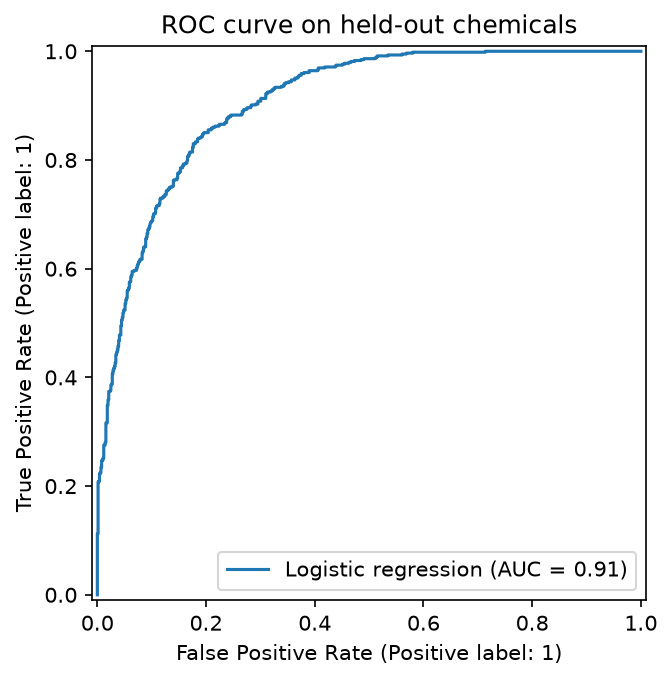

In [7]:
RocCurveDisplay.from_predictions(y_test, probabilities, name="Logistic regression")
plt.title("ROC curve on held-out chemicals")
plt.savefig(output / "logistic_regression_roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

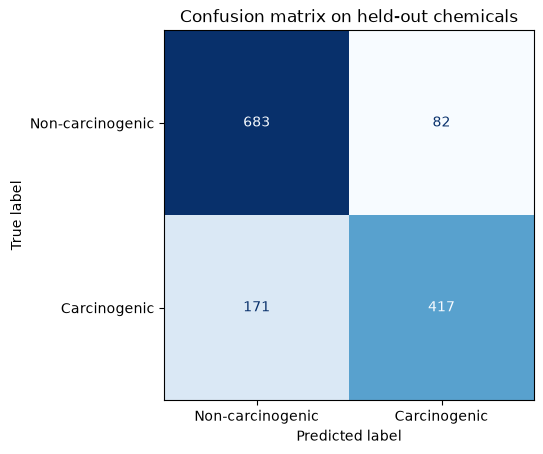

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=["Non-carcinogenic", "Carcinogenic"],
    cmap="Blues", colorbar=False,
)
plt.title("Confusion matrix on held-out chemicals")
plt.savefig(output / "logistic_regression_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

On unseen chemicals, the model classified 81.3% of test records correctly, and 83.6% of its carcinogenic predictions were correct. It identified 70.9% of the carcinogenic test records and achieved a ROC-AUC of 0.905.